# BM25 vs Dense vs Hybrid Retrieval: A Comparative Study on NFCorpus

**Research question:** Does semantic (dense) retrieval outperform traditional keyword-based (BM25) retrieval for biomedical question answering, and where does each approach have an advantage?

**Dataset:** NFCorpus (BEIR benchmark), test split: 323 nutrition/health queries against 3,633 PubMed abstracts with graded relevance judgments (qrels).

**Pipeline:**
```
Query - BM25                 -> Top-k documents
      - Dense retrieval      -> Top-k documents
      - Hybrid (RRF)         -> Top-k documents
```

**Metrics:** Recall@1/5/10, MRR (original run); MRR@10, nDCG@10 and paired significance tests (Phase 8).

**NOTE:** from the repository root (so that `ir_utils.py` is importable) run all cells in order.


In [20]:
# Dependencies: see requirements.txt
# pip install -r requirements.txt
import re
from collections import defaultdict

import faiss
import ir_datasets
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from rank_bm25 import BM25Okapi
from sentence_transformers import SentenceTransformer
from tqdm.auto import tqdm

np.random.seed(42)


## Phase 1: Load Dataset

Using the BEIR version of NFCorpus via `ir_datasets`. We got 3 things:
- **Corpus**: documents to search over (PubMed abstracts, each with a title + text)
- **Queries**: natural-language nutrition/health questions
- **Qrels**: ground-truth relevance judgments (query_id, doc_id, relevance grade)

We use the `test` split, which is the standard evaluation split reported in
BEIR-style papers.

In [21]:
dataset = ir_datasets.load("beir/nfcorpus/test")

# --- Corpus ---
doc_ids = []
doc_texts = []
for doc in tqdm(dataset.docs_iter(), desc="Loading corpus"):
    doc_ids.append(doc.doc_id)
    # Combine title + text, as is standard practice for BEIR corpora
    combined = (doc.title + ". " + doc.text) if doc.title else doc.text
    doc_texts.append(combined)

doc_id_to_idx = {doc_id: i for i, doc_id in enumerate(doc_ids)}

# --- Queries ---
query_ids = []
query_texts = []
for query in dataset.queries_iter():
    query_ids.append(query.query_id)
    query_texts.append(query.text)

# --- Qrels: query_id -> {doc_id: relevance} ---
qrels = defaultdict(dict)
for qrel in dataset.qrels_iter():
    qrels[qrel.query_id][qrel.doc_id] = qrel.relevance

print(f"Corpus size: {len(doc_ids)} documents")
print(f"Number of queries: {len(query_ids)}")
print(f"Number of queries with qrels: {len(qrels)}")

# Keep only queries that actually have at least one relevant (relevance > 0) doc
def has_relevant_doc(qid):
    return any(rel > 0 for rel in qrels.get(qid, {}).values())

eval_query_ids = [qid for qid in query_ids if qid in qrels and has_relevant_doc(qid)]
eval_query_texts = [query_texts[query_ids.index(qid)] for qid in eval_query_ids]
print(f"Queries usable for evaluation (have >=1 relevant doc): {len(eval_query_ids)}")

Loading corpus: 0it [00:00, ?it/s]

[INFO] Opening C:\Users\Aaditya Dalal\.ir_datasets\beir\nfcorpus/docs.pklz4\bin with direct file access


Corpus size: 3633 documents
Number of queries: 323
Number of queries with qrels: 323
Queries usable for evaluation (have >=1 relevant doc): 323


## Phase 2: BM25 (Sparse) Retrieval

BM25 scores documents by term-frequency / inverse-document-frequency,
with length normalization. It requires no training, just tokenized text.

In [22]:
def simple_tokenize(text):
    return re.findall(r"[a-z0-9]+", text.lower())

print("Tokenizing corpus for BM25...")
tokenized_corpus = [simple_tokenize(t) for t in tqdm(doc_texts)]
bm25 = BM25Okapi(tokenized_corpus)

def bm25_retrieve(query_text, k=10):
    tokenized_query = simple_tokenize(query_text)
    scores = bm25.get_scores(tokenized_query)
    top_idx = np.argsort(scores)[::-1][:k]
    return [doc_ids[i] for i in top_idx]

# Sanity check on one query
print(eval_query_texts[0])
print(bm25_retrieve(eval_query_texts[0], k=5))


Tokenizing corpus for BM25...


  0%|          | 0/3633 [00:00<?, ?it/s]

Do Cholesterol Statin Drugs Cause Breast Cancer?
['MED-14', 'MED-2429', 'MED-10', 'MED-2428', 'MED-1193']


## Phase 3: Dense Retrieval

We embed every document and query with a pretrained sentence-transformer
(`all-MiniLM-L6-v2` the same model family used in a lot of BEIR papers)
and retrieve by cosine similarity, implemented as inner product on
L2-normalized vectors via FAISS.

In [23]:
model = SentenceTransformer("all-MiniLM-L6-v2")

print("Encoding corpus (this can take a few minutes on CPU)...")
doc_embeddings = model.encode(
    doc_texts, batch_size=64, show_progress_bar=True, convert_to_numpy=True
)
faiss.normalize_L2(doc_embeddings)

index = faiss.IndexFlatIP(doc_embeddings.shape[1])
index.add(doc_embeddings)

print("Encoding queries...")
query_embeddings = model.encode(
    eval_query_texts, batch_size=64, show_progress_bar=True, convert_to_numpy=True
)
faiss.normalize_L2(query_embeddings)

def dense_retrieve_batch(k=10):
    scores, idxs = index.search(query_embeddings, k)
    return [[doc_ids[i] for i in row] for row in idxs]

dense_results_top10 = dense_retrieve_batch(k=10)
print(eval_query_texts[0])
print(dense_results_top10[0][:5])


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Encoding corpus (this can take a few minutes on CPU)...


Batches:   0%|          | 0/57 [00:00<?, ?it/s]

Encoding queries...


Batches:   0%|          | 0/6 [00:00<?, ?it/s]

Do Cholesterol Statin Drugs Cause Breast Cancer?
['MED-2440', 'MED-2429', 'MED-10', 'MED-2431', 'MED-14']


## Phase 4: Hybrid Retrieval (Reciprocal Rank Fusion)

RRF combines two ranked lists without needing to tune score weights (BM25
scores and cosine similarities live on different scales, so summing them
directly is unprincipled). For each document, its RRF score is:

$$\text{RRF}(d) = \sum_{\text{system} \in \{BM25, Dense\}} \frac{1}{c + rank_{\text{system}}(d)}$$

with the standard constant $c = 60$.

In [24]:
def reciprocal_rank_fusion(rank_lists, c=60, k=10):
    """rank_lists: list of ranked doc_id lists (e.g. [bm25_list, dense_list])"""
    scores = defaultdict(float)
    for ranked_list in rank_lists:
        for rank, doc_id in enumerate(ranked_list):
            scores[doc_id] += 1.0 / (c + rank + 1)
    ranked = sorted(scores.items(), key=lambda x: x[1], reverse=True)
    return [doc_id for doc_id, _ in ranked[:k]]

K_RETRIEVE = 100  # retrieve deep candidate lists before fusing/truncating to eval k
bm25_results_top100 = [bm25_retrieve(q, k=K_RETRIEVE) for q in tqdm(eval_query_texts, desc="BM25 retrieval")]
dense_results_top100 = dense_retrieve_batch(k=K_RETRIEVE)

hybrid_results_top10 = [
    reciprocal_rank_fusion([bm25_results_top100[i], dense_results_top100[i]], k=10)
    for i in range(len(eval_query_ids))
]
print(hybrid_results_top10[0][:5])


BM25 retrieval:   0%|          | 0/323 [00:00<?, ?it/s]

['MED-2429', 'MED-14', 'MED-10', 'MED-2431', 'MED-4827']


## Phase 5: Evaluation Metrics

- **Recall@k**: fraction of *relevant* docs (relevance > 0 in qrels) that appear in the top-k
- **MRR**: 1 / rank of the first relevant doc retrieved (0 if none found in top-k)

In [25]:
def recall_at_k(retrieved, relevant_set, k):
    if not relevant_set:
        return None
    top_k = set(retrieved[:k])
    return len(top_k & relevant_set) / len(relevant_set)

def reciprocal_rank(retrieved, relevant_set):
    for rank, doc_id in enumerate(retrieved, start=1):
        if doc_id in relevant_set:
            return 1.0 / rank
    return 0.0

def evaluate_system(results_top100_or_10, qids, name):
    r1s, r5s, r10s, mrrs = [], [], [], []
    for qid, retrieved in zip(qids, results_top100_or_10):
        relevant_set = {d for d, rel in qrels[qid].items() if rel > 0}
        r1 = recall_at_k(retrieved, relevant_set, 1)
        r5 = recall_at_k(retrieved, relevant_set, 5)
        r10 = recall_at_k(retrieved, relevant_set, 10)
        mrr = reciprocal_rank(retrieved, relevant_set)
        if r1 is not None:
            r1s.append(r1); r5s.append(r5); r10s.append(r10); mrrs.append(mrr)
    return {
        "System": name,
        "Recall@1": np.mean(r1s),
        "Recall@5": np.mean(r5s),
        "Recall@10": np.mean(r10s),
        "MRR": np.mean(mrrs),
    }

results_table = pd.DataFrame([
    evaluate_system(bm25_results_top100, eval_query_ids, "BM25"),
    evaluate_system(dense_results_top100, eval_query_ids, "Dense (MiniLM)"),
    evaluate_system(hybrid_results_top10, eval_query_ids, "Hybrid (RRF)"),
])
results_table = results_table.round(4)
results_table


,System,Recall@1,Recall@5,Recall@10,MRR
0,BM25,0.0565,0.1150,0.1524,0.5113
1,Dense (MiniLM),0.0436,0.1187,0.1589,0.5121
2,Hybrid (RRF),0.0551,0.1293,0.1612,0.5422


## Phase 6: Visualization

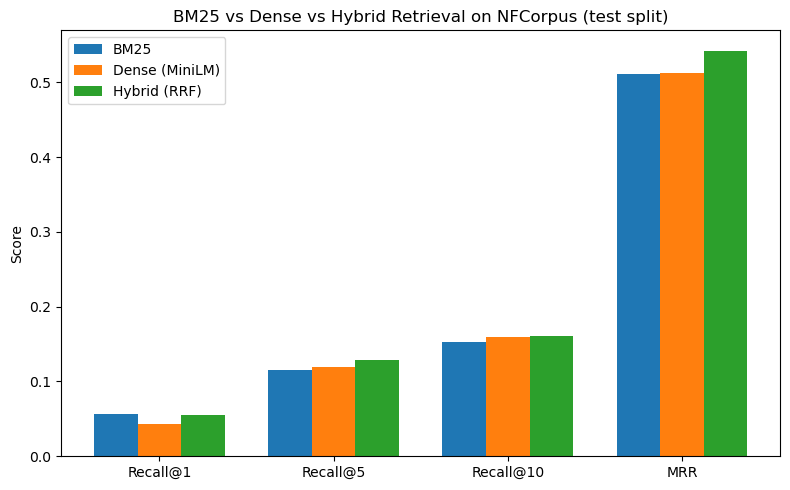

In [26]:
metrics = ["Recall@1", "Recall@5", "Recall@10", "MRR"]
x = np.arange(len(metrics))
width = 0.25

fig, ax = plt.subplots(figsize=(8, 5))
for i, row in results_table.iterrows():
    ax.bar(x + i * width, [row[m] for m in metrics], width, label=row["System"])

ax.set_xticks(x + width)
ax.set_xticklabels(metrics)
ax.set_ylabel("Score")
ax.set_title("BM25 vs Dense vs Hybrid Retrieval on NFCorpus (test split)")
ax.legend()
plt.tight_layout()
plt.savefig("retrieval_comparison.png", dpi=150)
plt.show()


## Phase 7: Error Analysis — Where Does Each Method Win?

Here we check,
per query, whether BM25 or Dense found the first relevant document sooner,
and correlate that with a simple proxy for exact-keyword overlap between the
query and its relevant document(s).

In [27]:
from ir_utils import lexical_overlap

In [28]:
import numpy as np

# Deterministic lexical overlap: mean over ALL relevant docs per query
rows = []
for i, qid in enumerate(eval_query_ids):
    relevant_set = {d for d, rel in qrels[qid].items() if rel > 0}
    if not relevant_set:
        continue
    bm25_rr = reciprocal_rank(bm25_results_top100[i], relevant_set)
    dense_rr = reciprocal_rank(dense_results_top100[i], relevant_set)
    overlap = np.mean([
        lexical_overlap(eval_query_texts[i], doc_texts[doc_id_to_idx[d]])
        for d in sorted(relevant_set)
    ])
    rows.append({
        "query_id": qid, "bm25_rr": bm25_rr, "dense_rr": dense_rr,
        "winner": "BM25" if bm25_rr > dense_rr else ("Dense" if dense_rr > bm25_rr else "Tie"),
        "lexical_overlap": overlap,
        "n_relevant": len(relevant_set),
    })
analysis_df = pd.DataFrame(rows)
analysis_df.to_csv("per_query_analysis.csv", index=False)

print(analysis_df.groupby("winner")["lexical_overlap"].describe())
print("\nAvg relevant docs per query:", analysis_df["n_relevant"].mean().round(1))

# Significance tests
rng = np.random.default_rng(42)
a = analysis_df.loc[analysis_df.winner == "BM25", "lexical_overlap"].values
b = analysis_df.loc[analysis_df.winner == "Dense", "lexical_overlap"].values
observed = a.mean() - b.mean()

pooled = np.concatenate([a, b]); n1 = len(a)
perm = np.empty(10000)
for k in range(10000):
    rng.shuffle(pooled)
    perm[k] = pooled[:n1].mean() - pooled[n1:].mean()
p_perm = (np.abs(perm) >= abs(observed)).mean()

boot = np.array([rng.choice(a, len(a)).mean() - rng.choice(b, len(b)).mean()
                 for _ in range(10000)])
ci = np.percentile(boot, [2.5, 97.5])

print(f"\nObserved diff: {observed:.4f}")
print(f"Permutation p-value: {p_perm:.4f}")
print(f"Bootstrap 95% CI: [{ci[0]:.4f}, {ci[1]:.4f}]")

        count      mean       std       min       25%       50%       75%  \
winner                                                                      
BM25     73.0  0.303429  0.189322  0.011858  0.166667  0.285714  0.380952   
Dense   101.0  0.195936  0.162554  0.000000  0.022059  0.193333  0.325000   
Tie     149.0  0.264302  0.260671  0.000000  0.060606  0.200000  0.378641   

         max  
winner        
BM25    1.00  
Dense   0.62  
Tie     1.00  

Avg relevant docs per query: 38.2

Observed diff: 0.1075
Permutation p-value: 0.0000
Bootstrap 95% CI: [0.0557, 0.1609]


## Phase 8: Additional analyses

The cells below address limitations of the original evaluation:

1. **Matched evaluation depth.** In Phase 5, BM25 and Dense were scored on their top-100 lists while Hybrid was scored on its top-10 list. Recall@k (k <= 10) is unaffected, but MRR for BM25/Dense could count relevant documents found at ranks 11-100 while Hybrid's could not. Here every system is truncated to the same depth (10) and we report **MRR@10** and **nDCG@10** (linear gain, as in BEIR).
2. **Paired significance tests** over queries for the differences between systems.
3. **Welch's t-test and Cohen's d** for the lexical-overlap comparison (the report quotes these).
4. **Qualitative examples** of queries each method wins.


In [29]:
from ir_utils import (ndcg_at_k, paired_bootstrap, permutation_test, bootstrap_diff_ci,
                      cohens_d, recall_at_k as r_at_k, reciprocal_rank as rr_fn)

DEPTH = 10
systems = {
    "BM25": [r[:DEPTH] for r in bm25_results_top100],
    "Dense (MiniLM)": [r[:DEPTH] for r in dense_results_top100],
    "Hybrid (RRF)": [r[:DEPTH] for r in hybrid_results_top10],
}

per_query = {name: defaultdict(list) for name in systems}
for name, runs in systems.items():
    for qid, retrieved in zip(eval_query_ids, runs):
        rel_set = {d for d, r in qrels[qid].items() if r > 0}
        per_query[name]["Recall@1"].append(r_at_k(retrieved, rel_set, 1))
        per_query[name]["Recall@5"].append(r_at_k(retrieved, rel_set, 5))
        per_query[name]["Recall@10"].append(r_at_k(retrieved, rel_set, 10))
        per_query[name]["MRR@10"].append(rr_fn(retrieved, rel_set, k=DEPTH))
        per_query[name]["nDCG@10"].append(ndcg_at_k(retrieved, qrels[qid], k=DEPTH))

matched_table = pd.DataFrame(
    [{"System": n, **{m: np.mean(v) for m, v in d.items()}} for n, d in per_query.items()]
).round(4)
matched_table

,System,Recall@1,Recall@5,Recall@10,MRR@10,nDCG@10
0,BM25,0.0565,0.1150,0.1524,0.5085,0.3070
1,Dense (MiniLM),0.0436,0.1187,0.1589,0.5068,0.3179
2,Hybrid (RRF),0.0551,0.1293,0.1612,0.5422,0.3350


### 8b. Paired bootstrap tests (queries are the resampling unit)

In [30]:
pairs = [("Hybrid (RRF)", "BM25"), ("Hybrid (RRF)", "Dense (MiniLM)"), ("Dense (MiniLM)", "BM25")]
rows = []
for a, b in pairs:
    for metric in ["Recall@1", "Recall@5", "Recall@10", "MRR@10", "nDCG@10"]:
        diff, (lo, hi), p = paired_bootstrap(per_query[a][metric], per_query[b][metric], n_boot=10000, seed=42)
        rows.append({"A": a, "B": b, "metric": metric, "mean(A)-mean(B)": diff,
                     "95% CI low": lo, "95% CI high": hi, "p (two-sided)": p})
paired_table = pd.DataFrame(rows).round(4)
paired_table

,A,B,metric,mean(A)-mean(B),95% CI low,95% CI high,p (two-sided)
0,Hybrid (RRF),BM25,Recall@1,-0.0014,-0.0091,0.0042,0.7889
1,Hybrid (RRF),BM25,Recall@5,0.0143,0.0046,0.0252,0.0034
2,Hybrid (RRF),BM25,Recall@10,0.0088,0.0001,0.0186,0.0486
3,Hybrid (RRF),BM25,MRR@10,0.0337,0.0104,0.0578,0.0036
4,Hybrid (RRF),BM25,nDCG@10,0.0280,0.0151,0.0414,0.0002
5,Hybrid (RRF),Dense (MiniLM),Recall@1,0.0115,0.0033,0.0221,0.0006
6,Hybrid (RRF),Dense (MiniLM),Recall@5,0.0106,-0.0034,0.0252,0.1336
7,Hybrid (RRF),Dense (MiniLM),Recall@10,0.0023,-0.0096,0.0146,0.7221
8,Hybrid (RRF),Dense (MiniLM),MRR@10,0.0354,0.0064,0.0640,0.0180
9,Hybrid (RRF),Dense (MiniLM),nDCG@10,0.0170,0.0018,0.0324,0.0268


### 8c. Lexical-overlap comparison: parametric cross-check

In [31]:
from scipy import stats

bm25_ov = analysis_df.loc[analysis_df.winner == "BM25", "lexical_overlap"].values
dense_ov = analysis_df.loc[analysis_df.winner == "Dense", "lexical_overlap"].values

t, p_t = stats.ttest_ind(bm25_ov, dense_ov, equal_var=False)
print(f"Welch t = {t:.2f}, p = {p_t:.5f}")
print(f"Cohen's d = {cohens_d(bm25_ov, dense_ov):.2f}")
diff, p_perm = permutation_test(bm25_ov, dense_ov, n_perm=10000, seed=42)
lo, hi = bootstrap_diff_ci(bm25_ov, dense_ov, n_boot=10000, seed=42)
print(f"diff = {diff:.4f}, permutation p = {p_perm:.5f} (+1 corrected), 95% bootstrap CI [{lo:.4f}, {hi:.4f}]")

Welch t = 3.92, p = 0.00014
Cohen's d = 0.62
diff = 0.1075, permutation p = 0.00010 (+1 corrected), 95% bootstrap CI [0.0559, 0.1606]


### 8d. Qualitative examples

In [32]:
qtext = dict(zip(eval_query_ids, eval_query_texts))
ex = analysis_df.assign(gap=analysis_df.bm25_rr - analysis_df.dense_rr)

def show(df, title):
    print("=" * 80); print(title); print("=" * 80)
    for _, r in df.iterrows():
        print(f"[{r.query_id}] {qtext[r.query_id]}")
        print(f"    BM25 RR={r.bm25_rr:.3f} | Dense RR={r.dense_rr:.3f} | lexical overlap={r.lexical_overlap:.2f}")

show(ex[ex.winner == "BM25"].nlargest(4, "gap"), "Largest BM25 wins")
show(ex[ex.winner == "Dense"].nsmallest(4, "gap"), "Largest Dense wins")

Largest BM25 wins
[PLAIN-1645] molasses
    BM25 RR=1.000 | Dense RR=0.000 | lexical overlap=0.17
[PLAIN-2019] rickets
    BM25 RR=1.000 | Dense RR=0.000 | lexical overlap=0.33
[PLAIN-2291] ultra-processed foods
    BM25 RR=1.000 | Dense RR=0.013 | lexical overlap=0.27
[PLAIN-1473] kohlrabi
    BM25 RR=1.000 | Dense RR=0.014 | lexical overlap=1.00
Largest Dense wins
[PLAIN-1929] prenatal vitamins
    BM25 RR=0.000 | Dense RR=1.000 | lexical overlap=0.00
[PLAIN-2970] Preventing Cataracts with Diet
    BM25 RR=0.000 | Dense RR=1.000 | lexical overlap=0.33
[PLAIN-3241] Apthous Ulcer Mystery Solved
    BM25 RR=0.000 | Dense RR=1.000 | lexical overlap=0.00
[PLAIN-1537] low-carb diets
    BM25 RR=0.091 | Dense RR=1.000 | lexical overlap=0.24


### 8e. Save results and Figure 2

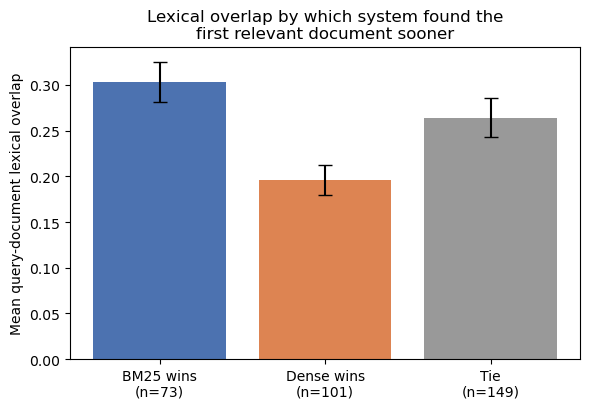

In [33]:
import os
os.makedirs("results", exist_ok=True); os.makedirs("figures", exist_ok=True)
results_table.to_csv("results/results_table.csv", index=False)
matched_table.to_csv("results/matched_depth_table.csv", index=False)
paired_table.to_csv("results/paired_bootstrap.csv", index=False)
analysis_df.to_csv("results/per_query_analysis.csv", index=False)

g = analysis_df.groupby("winner")["lexical_overlap"]
order = ["BM25", "Dense", "Tie"]
means = g.mean().reindex(order); sems = (g.std() / np.sqrt(g.count())).reindex(order)
counts = g.count().reindex(order)
fig, ax = plt.subplots(figsize=(6, 4.2))
ax.bar([f"{w} wins\n(n={counts[w]})" if w != "Tie" else f"Tie\n(n={counts[w]})" for w in order],
       means, yerr=sems, capsize=5, color=["#4c72b0", "#dd8452", "#999999"])
ax.set_ylabel("Mean query-document lexical overlap")
ax.set_title("Lexical overlap by which system found the\nfirst relevant document sooner")
plt.tight_layout(); plt.savefig("figures/lexical_overlap_by_winner.png", dpi=200); plt.show()